In [3]:
import numpy as np
import csv
import matplotlib.pyplot as plt
import pandas as pd
import pathlib as Path

In [4]:
DAYS_PER_MONTH = 30
HOURS_PER_DAY = 16
N_LANES = 50
E_B = 1.0

In [ ]:
# Searches your user directory (Desktop, Documents, Downloads, repos, etc.) for airport.csv
# matches = list(Path.Path.home().rglob("airport.csv"))
print("Using airport.csv from the notebook workspace.")

KeyboardInterrupt: 

In [7]:
pathname = "airport.csv"
df = pd.read_csv(pathname)
# df = pd.read_csv(matches[0])

In [9]:
with open(pathname, newline="", encoding="utf-8") as csvfile:
    rows = list(csv.DictReader(csvfile))

september_rows = [
    row for row in rows
    if row["Month"] == "September" and 2015 <= int(row["Year"]) <= 2019
]

numeric_columns = [
    column for column in rows[0]
    if column not in ("Year", "Month")
]

september_average = {
    column: np.mean([int(row[column]) for row in september_rows])
    for column in numeric_columns
}

print(f"September rows: {len(september_rows)}")
for column, average in september_average.items():
    print(f"{column}: {average:.2f}")

September rows: 6
Europe Flights: 34973.67
Intercontinental Flights: 7698.17
Total Flights: 42671.83
Europe Passengers: 4246296.67
Intercontinental Passengers: 1698327.17
Total Passengers: 5944623.83


In [10]:
df

,Year,Month,Europe Flights,Intercontinental Flights,Total Flights,Europe Passengers,Intercontinental Passengers,Total Passengers
0,2014,January,24728,6664,31392,2301528,1315024,3616552
1,2014,February,23394,6056,29450,2289187,1146405,3435592
2,2014,March,27140,6893,34033,2744289,1332183,4076472
3,2014,April,29742,6888,36630,3168885,1391757,4560642
4,2014,May,32356,7137,39493,3537385,1450566,4987951
...,...,...,...,...,...,...,...,...
127,2024,August,35277,7841,43118,4618422,1798617,6417039
128,2024,September,33180,8598,41778,4170524,1860289,6030813
129,2024,October,34487,7518,42005,4371263,1667703,6038966
130,2024,November,29574,7014,36588,3572442,1498744,5071186


In [11]:
pre_covid = df.iloc[0:][0:72]

In [12]:
pre_covid

,Year,Month,Europe Flights,Intercontinental Flights,Total Flights,Europe Passengers,Intercontinental Passengers,Total Passengers
0,2014,January,24728,6664,31392,2301528,1315024,3616552
1,2014,February,23394,6056,29450,2289187,1146405,3435592
2,2014,March,27140,6893,34033,2744289,1332183,4076472
3,2014,April,29742,6888,36630,3168885,1391757,4560642
4,2014,May,32356,7137,39493,3537385,1450566,4987951
...,...,...,...,...,...,...,...,...
67,2019,August,36867,8255,45122,4804762,2005997,6810759
68,2019,September,36193,7938,44131,4649227,1844241,6493468
69,2019,October,36508,7995,44503,4600170,1831273,6431443
70,2019,November,30599,7203,37802,3713816,1609774,5323590


In [13]:
means = pre_covid.mean(numeric_only=True)

In [14]:
for name, value in means.items():
    print(f"{name}: {value:.0f}")

Year: 2016
Europe Flights: 32281
Intercontinental Flights: 7453
Total Flights: 39734
Europe Passengers: 3790002
Intercontinental Passengers: 1595524
Total Passengers: 5385526
Year: 2016
Europe Flights: 32281
Intercontinental Flights: 7453
Total Flights: 39734
Europe Passengers: 3790002
Intercontinental Passengers: 1595524
Total Passengers: 5385526
Year: 2016
Europe Flights: 32281
Intercontinental Flights: 7453
Total Flights: 39734
Europe Passengers: 3790002
Intercontinental Passengers: 1595524
Total Passengers: 5385526
Year: 2016
Europe Flights: 32281
Intercontinental Flights: 7453
Total Flights: 39734
Europe Passengers: 3790002
Intercontinental Passengers: 1595524
Total Passengers: 5385526
Year: 2016
Europe Flights: 32281
Intercontinental Flights: 7453
Total Flights: 39734
Europe Passengers: 3790002
Intercontinental Passengers: 1595524
Total Passengers: 5385526
Year: 2016
Europe Flights: 32281
Intercontinental Flights: 7453
Total Flights: 39734
Europe Passengers: 3790002
Intercontinen

In [17]:
# df = pd.read_csv(matches[0])
sep = df[(df["Month"] == "September") & (df["Year"].between(2015, 2019))]

In [18]:
P_bar = sep["Total Passengers"].mean()                 
per_hour_airport = P_bar / (DAYS_PER_MONTH * HOURS_PER_DAY)
per_hour_lane = per_hour_airport / N_LANES
lam = per_hour_lane / 60                              

rho_baseline = lam * E_B # 1 server
rho_option_a = lam * E_B / 2 # 2 servers

In [19]:
print(sep[["Year", "Total Passengers"]].to_string(index=False))
print(f"\nAverage September passengers : {P_bar:,.1f}")
print(f"Airport-wide arrivals / hour : {per_hour_airport:,.2f}")
print(f"Per-lane arrivals / hour     : {per_hour_lane:,.2f}")
print(f"lambda (per lane, per min)   : {lam:.4f}")
print(f"rho baseline / Option B (c=1): {rho_baseline:.4f}")
print(f"rho Option A (c=2)           : {rho_option_a:.4f}")

 Year  Total Passengers
 2015           5466239
 2016           5866487
 2017           6259104
 2018           6396940
 2019           6493468

Average September passengers : 6,096,447.6
Airport-wide arrivals / hour : 12,700.93
Per-lane arrivals / hour     : 254.02
lambda (per lane, per min)   : 4.2336
rho baseline / Option B (c=1): 4.2336
rho Option A (c=2)           : 2.1168


In [21]:
import heapq
import numpy as np
from scipy import stats

In [22]:
ARRIVAL, DEPARTURE = 0, 1

In [23]:
def sample_service(rng, mean, sd):
    s = rng.normal(mean, sd)
    while s < 0:
        s = rng.normal(mean, sd)
    return s

In [24]:
def simulate(lam, mean_s, sd_s, n_servers, n_passengers, seed=None):
    rng = np.random.default_rng(seed)
    fel = []                                  
    waits = np.empty(n_passengers)
    arrival_time = np.empty(n_passengers)
    queue = []                                
    q_head = 0
    busy = 0
    n_arrived = 0

    # schedule first arrival
    heapq.heappush(fel, (rng.exponential(1.0 / lam), ARRIVAL, 0))

    while fel:
        t, etype, pid = heapq.heappop(fel)

        if etype == ARRIVAL:
            arrival_time[pid] = t
            n_arrived += 1
            if n_arrived < n_passengers:      
                heapq.heappush(fel, (t + rng.exponential(1.0 / lam), ARRIVAL, pid + 1))
            if busy < n_servers:             
                busy += 1
                waits[pid] = 0.0
                heapq.heappush(fel, (t + sample_service(rng, mean_s, sd_s), DEPARTURE, pid))
            else:
                queue.append(pid)

        else:  # departure
            if q_head < len(queue):         
                nxt = queue[q_head]
                q_head += 1
                waits[nxt] = t - arrival_time[nxt]
                heapq.heappush(fel, (t + sample_service(rng, mean_s, sd_s), DEPARTURE, nxt))
            else:
                busy -= 1

    return waits

In [25]:
E_B, SIGMA = 1.0, 0.25
RHO_TARGET = 0.85
R = 40                  
WARMUP = 1000          
N_PER_REP = 51_000      
ALPHA = 0.05

lam_test = RHO_TARGET / E_B
rho_test = lam_test * E_B

assert rho_test < 1

ES2 = E_B**2 + SIGMA**2
Wq_theory = lam_test * ES2 / (2 * (1 - rho_test))
seeds = np.random.SeedSequence(2025).spawn(R)

rep_means = np.array([
    simulate(lam_test, E_B, SIGMA, 1, N_PER_REP, seed=s)[WARMUP:].mean()
    for s in seeds
])
Wq_sim = rep_means.mean()
sd = rep_means.std(ddof=1)
se = sd / np.sqrt(R)

t_stat, p_val = stats.ttest_1samp(rep_means, Wq_theory)
t_crit = stats.t.ppf(1 - ALPHA / 2, R - 1)
ci = (Wq_sim - t_crit * se, Wq_sim + t_crit * se)

print(f"lambda_test = {lam_test:.3f}, rho_test = {rho_test:.3f}")
print(f"E[S^2] = {ES2:.4f}")
print(f"Wq_theory (P-K)      = {Wq_theory:.4f} min")
print(f"Wq_sim (mean of {R})  = {Wq_sim:.4f} min   (sd of rep means = {sd:.4f}, SE = {se:.4f})")
print(f"95% CI for Wq_sim    = ({ci[0]:.4f}, {ci[1]:.4f})")
print(f"t = {t_stat:.4f}, df = {R-1}, critical |t| = {t_crit:.4f}, p-value = {p_val:.4f}")
print("Reject H0" if p_val < ALPHA else "Fail to reject H0 -> simulator validated at alpha=0.05")


lambda_test = 0.850, rho_test = 0.850
E[S^2] = 1.0625
Wq_theory (P-K)      = 3.0104 min
Wq_sim (mean of 40)  = 3.0135 min   (sd of rep means = 0.1746, SE = 0.0276)
95% CI for Wq_sim    = (2.9576, 3.0693)
t = 0.1114, df = 39, critical |t| = 2.0227, p-value = 0.9119
Fail to reject H0 -> simulator validated at alpha=0.05


In [29]:
# plotting:
def plot_historical_september_trend(df, baseline_years=(2015, 2019)):
    sep_all = df[df["Month"] == "September"].sort_values("Year")
    y_min, y_max = baseline_years

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        df.index,
        df["Total Passengers"] / 1e6,
        color="lightgray",
        linewidth=1.5,
        label="All Monthly Traffic",
    )
    ax.scatter(
        sep_all.index,
        sep_all["Total Passengers"] / 1e6,
        color="#1f77b4",
        zorder=4,
        label="September Traffic",
    )

    in_base = sep_all["Year"].between(y_min, y_max)
    ax.scatter(
        sep_all.loc[in_base].index,
        sep_all.loc[in_base, "Total Passengers"] / 1e6,
        color="#d62728",
        s=75,
        zorder=5,
        label=f"Baseline Septembers ({y_min}–{y_max})",
    )

    tick_idx = df.index[::12]
    ax.set_xticks(tick_idx)
    ax.set_xticklabels(df.loc[tick_idx, "Year"], rotation=45)
    ax.set_ylabel("Total Passengers (Millions)")
    ax.set_title("Monthly Passenger Volume and September Baseline Selection")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    return fig, ax

In [30]:
def plot_service_time_distribution(mean_s=1.0, sd_list=(0.25, 0.10), n_samples=100_000, seed=42):
    rng = np.random.default_rng(seed)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    for sd in sd_list:
        samples = np.array([sample_service(rng, mean_s, sd) for _ in range(n_samples)])
        ax.hist(
            samples,
            bins=60,
            density=True,
            alpha=0.5,
            label=f"Truncated Normal (mean={mean_s:.2f}, sd={sd:.2f}, empirical mean={samples.mean():.4f})",
        )

    ax.axvline(0, color="black", linestyle="--", linewidth=1.2, label="Non-negativity bound (0 min)")
    ax.set_xlabel("Service Time per Passenger (minutes)")
    ax.set_ylabel("Density")
    ax.set_title("Simulated Service Time Distributions (Baseline / Option A vs. Option B)")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    return fig, ax

In [31]:
def plot_utilization_regime(lam, e_b=1.0):
    scenarios = ["Single-Server\n(Baseline / Opt. B)", "Two-Server Lane\n(Option A)"]
    rhos = [lam * e_b, (lam * e_b) / 2.0]
    capacities = [1.0 / e_b, 2.0 / e_b]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 4.2))

    ax1.bar(scenarios, capacities, color="#4c72b0", width=0.5, label="Lane Service Capacity (pax/min)")
    ax1.axhline(lam, color="#d62728", linestyle="--", linewidth=1.8, label=f"Arrival Rate λ = {lam:.2f} pax/min")
    ax1.set_ylabel("Passengers per Minute")
    ax1.set_title("Arrival Rate vs. Service Capacity")
    ax1.legend(frameon=False)
    ax1.grid(axis="y", alpha=0.25)

    colors = ["#d62728" if r > 1 else "#2ca02c" for r in rhos]
    bars = ax2.bar(scenarios, rhos, color=colors, width=0.5)
    ax2.axhline(1.0, color="black", linestyle=":", linewidth=1.5, label="Stability Threshold (ρ = 1.0)")
    for bar, r in zip(bars, rhos):
        ax2.text(bar.get_x() + bar.get_width() / 2, r + 0.08, f"ρ = {r:.2f}", ha="center", fontweight="bold")
    ax2.set_ylabel("Utilization (ρ)")
    ax2.set_title("Implied Traffic Intensity by Lane Setup")
    ax2.legend(frameon=False)
    ax2.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    return fig, (ax1, ax2)

In [32]:
def plot_pk_validation(rep_means, wq_theory, wq_sim, ci, alpha=0.05):
    reps = np.arange(1, len(rep_means) + 1)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(reps, rep_means, "o-", markersize=4.5, color="#1f77b4", alpha=0.8, label="Replication Mean Wait (Wq)")
    ax.axhline(wq_theory, color="#d62728", linestyle="--", linewidth=2, label=f"P-K Theory = {wq_theory:.4f} min")
    ax.axhline(wq_sim, color="#2ca02c", linestyle="-", linewidth=1.8, label=f"Sim Mean = {wq_sim:.4f} min")
    ax.axhspan(ci[0], ci[1], color="#2ca02c", alpha=0.15, label=f"{int((1 - alpha)*100)}% CI ({ci[0]:.4f}, {ci[1]:.4f})")

    ax.set_xlabel("Replication Index")
    ax.set_ylabel("Post-Warm-Up Mean Wait (minutes)")
    ax.set_title("Part 2A Validation: 40 Replications vs. Pollaczek–Khintchine Formula (ρ = 0.85)")
    ax.legend(frameon=False, loc="upper right")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    return fig, ax

In [33]:
def plot_warmup_convergence(lam_test, mean_s, sd_s, n_servers, n_passengers, warmup=1000, n_curves=10, seed=2025):
    seeds = np.random.SeedSequence(seed).spawn(n_curves)
    pax_idx = np.arange(1, n_passengers + 1)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    for s in seeds:
        waits = simulate(lam_test, mean_s, sd_s, n_servers, n_passengers, seed=s)
        cum_mean = np.cumsum(waits) / pax_idx
        ax.plot(pax_idx, cum_mean, alpha=0.65, linewidth=1.2)

    ax.axvline(warmup, color="#d62728", linestyle="--", linewidth=1.8, label=f"Warm-up Cutoff ({warmup:,} passengers)")
    ax.set_xlabel("Passenger Index")
    ax.set_ylabel("Cumulative Mean Wait Time (minutes)")
    ax.set_title("Cumulative Average Wait Time and Warm-Up Truncation Check")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    return fig, ax

In [34]:
def plot_transient_trajectories(scenario_waits_dict, window=100):
    """
    scenario_waits_dict: mapping scenario name -> 2D array of shape (R, 3000)
    containing wait times for each passenger across R replications.
    """
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    kernel = np.ones(window) / window

    for name, waits_2d in scenario_waits_dict.items():
        # Rolling average per replication to smooth passenger-to-passenger noise
        smoothed = np.array([np.convolve(row, kernel, mode="valid") for row in waits_2d])
        mean_curve = smoothed.mean(axis=0)
        q_low, q_high = np.percentile(smoothed, [2.5, 97.5], axis=0)
        x = np.arange(window, waits_2d.shape[1] + 1)

        line, = ax.plot(x, mean_curve, linewidth=2, label=f"{name} (mean across reps)")
        ax.fill_between(x, q_low, q_high, color=line.get_color(), alpha=0.18)

    ax.set_xlabel(f"Passenger Index ({window}-Passenger Rolling Average)")
    ax.set_ylabel("Waiting Time in Queue (minutes)")
    ax.set_title("Part 2B Transient Dynamics: Queue Wait Growth Across 3,000 Passengers")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    return fig, ax

In [35]:
def plot_scenario_hypothesis_comparison(rep_means_dict, alpha=0.05):
    """
    rep_means_dict: mapping scenario name -> 1D array of length R
    containing each replication's overall average wait time across 3,000 passengers.
    """
    names = list(rep_means_dict.keys())
    data = [np.asarray(rep_means_dict[k]) for k in names]
    means = np.array([d.mean() for d in data])
    ses = np.array([d.std(ddof=1) / np.sqrt(len(d)) for d in data])
    t_crits = np.array([stats.t.ppf(1 - alpha / 2, len(d) - 1) for d in data])
    cis = t_crits * ses

    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    ax.boxplot(data, tick_labels=names, patch_artist=True, widths=0.45,
               boxprops=dict(facecolor="#e6f0fa", color="#1f77b4"),
               medianprops=dict(color="#d62728", linewidth=2))

    x_pos = np.arange(1, len(names) + 1)
    ax.errorbar(x_pos, means, yerr=cis, fmt="D", color="black", capsize=5, label=f"Mean ± {int((1-alpha)*100)}% CI")

    ax.set_ylabel("Replication Mean Wait Time (minutes)")
    ax.set_title("Part 2B Scenario Comparison Across 40 Replications (3,000 Passengers)")
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    return fig, ax

In [36]:
def plot_arrival_sensitivity(rho_values, mean_s=1.0, sd_s=0.25, n_servers=1, n_passengers=3000, n_reps=20, seed=123):
    """
    Explores how 3,000-passenger mean wait time behaves across arrival intensities (rho),
    helping connect idealized uniform assumptions to peak-hour spikes or alternative strategies.
    """
    base_seq = np.random.SeedSequence(seed)
    all_means = []
    all_cis = []

    for idx, rho in enumerate(rho_values):
        lam_val = rho / mean_s
        rep_seeds = base_seq.spawn(n_reps) if idx == 0 else np.random.SeedSequence(seed + idx).spawn(n_reps)
        m = np.array([
            simulate(lam_val, mean_s, sd_s, n_servers, n_passengers, seed=s).mean()
            for s in rep_seeds
        ])
        se = m.std(ddof=1) / np.sqrt(n_reps)
        t_c = stats.t.ppf(0.975, n_reps - 1)
        all_means.append(m.mean())
        all_cis.append(t_c * se)

    all_means = np.array(all_means)
    all_cis = np.array(all_cis)

    fig, ax = plt.subplots(figsize=(8.8, 4.5))
    ax.errorbar(rho_values, all_means, yerr=all_cis, fmt="o-", capsize=4, color="#1f77b4", linewidth=2)
    ax.axvline(1.0, color="#d62728", linestyle="--", linewidth=1.5, label="Capacity Threshold (ρ = 1.0)")
    ax.set_xlabel("Effective Utilization Factor (ρ = λ · E[B] / c)")
    ax.set_ylabel("Mean Wait Time Over 3,000 Passengers (minutes)")
    ax.set_title("Sensitivity of Transient Wait Times to Arrival Intensity / Capacity Assumptions")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    return fig, ax

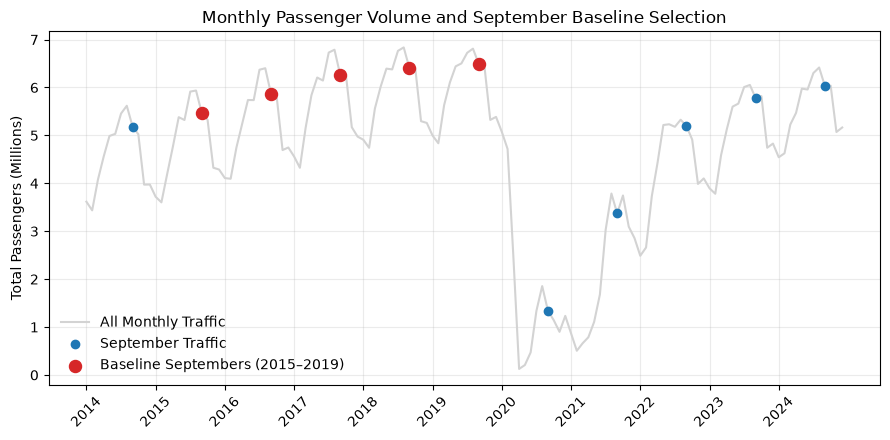

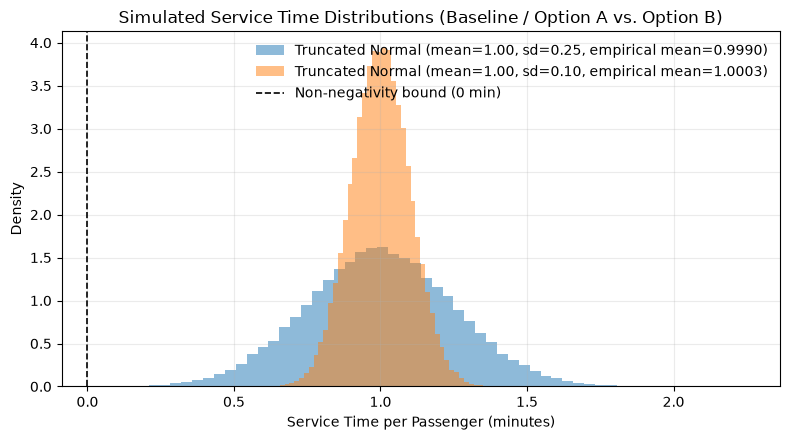

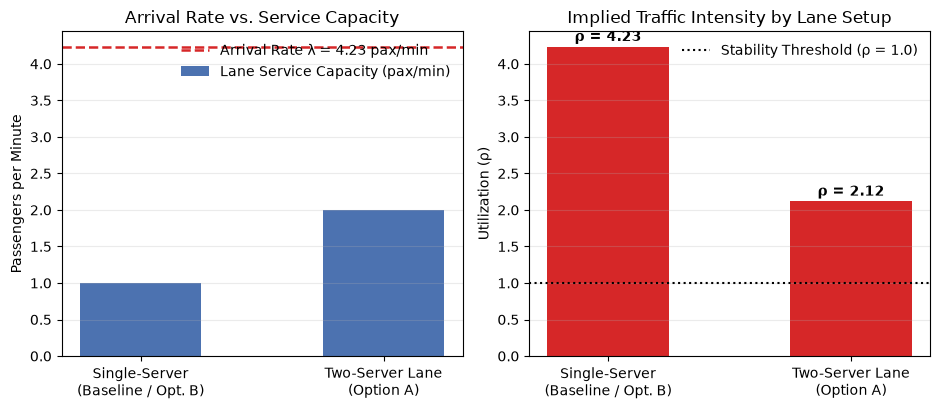

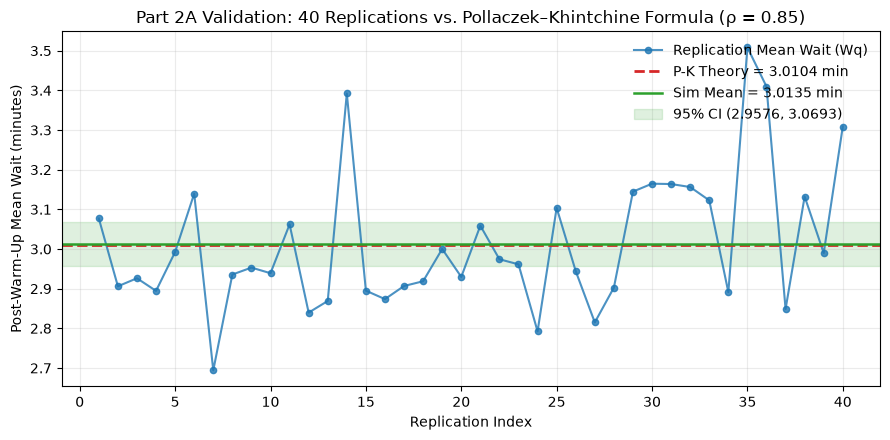

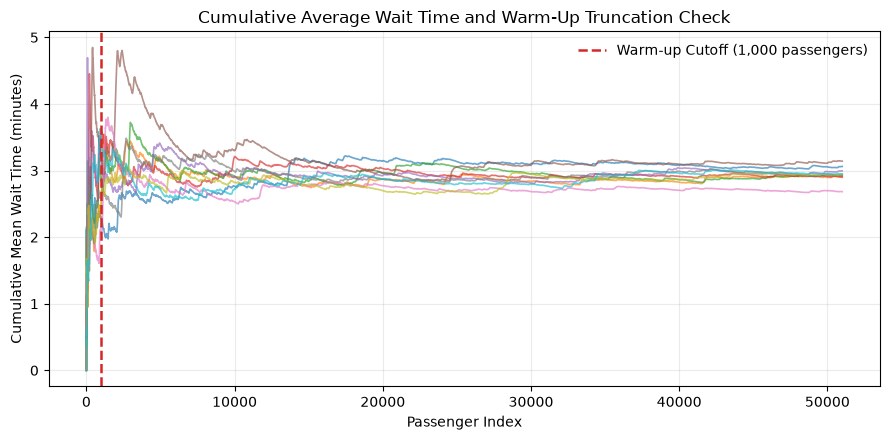

In [37]:
# Plot 1: Historical passenger trend & September baseline selection
fig1, ax1 = plot_historical_september_trend(df, baseline_years=(2015, 2019))
plt.show()

# Plot 2: Truncated normal service time distribution check
fig2, ax2 = plot_service_time_distribution(mean_s=E_B, sd_list=(0.25, 0.10))
plt.show()

# Plot 3: Arrival rate vs. capacity & utilization regime
fig3, ax3 = plot_utilization_regime(lam=lam, e_b=E_B)
plt.show()

# Plot 4: 40-replication validation against P-K analytical formula
fig4, ax4 = plot_pk_validation(
    rep_means=rep_means,
    wq_theory=Wq_theory,
    wq_sim=Wq_sim,
    ci=ci,
    alpha=ALPHA,
)
plt.show()

# Plot 5: Cumulative wait convergence & warm-up cutoff check
fig5, ax5 = plot_warmup_convergence(
    lam_test=lam_test,
    mean_s=E_B,
    sd_s=SIGMA,
    n_servers=1,
    n_passengers=N_PER_REP,
    warmup=WARMUP,
)
plt.show()

In [38]:
import json

R_2B = 40
N_PAX_2B = 3000
ALPHA = 0.05
RESULTS_FILE = "part2b_results.txt"

scenarios_2b = {
    "Baseline (c=1, σ=0.25)": {"n_servers": 1, "sd_s": 0.25},
    "Option A (c=2, σ=0.25)": {"n_servers": 2, "sd_s": 0.25},
    "Option B (c=1, σ=0.10)": {"n_servers": 1, "sd_s": 0.10},
}

scenario_waits_dict = {}
rep_means_dict = {}

for idx, (name, cfg) in enumerate(scenarios_2b.items()):
    seeds_2b = np.random.SeedSequence(3000 + idx).spawn(R_2B)
    waits_2d = np.array([
        simulate(lam, E_B, cfg["sd_s"], cfg["n_servers"], N_PAX_2B, seed=s)
        for s in seeds_2b
    ])
    scenario_waits_dict[name] = waits_2d
    rep_means_dict[name] = waits_2d.mean(axis=1)

# Save to a plain-text JSON file for instant reloading
payload = {
    "meta": {
        "lam": float(lam),
        "E_B": float(E_B),
        "R_2B": R_2B,
        "N_PAX_2B": N_PAX_2B,
    },
    "rep_means_dict": {k: v.tolist() for k, v in rep_means_dict.items()},
    "scenario_waits_dict": {k: v.tolist() for k, v in scenario_waits_dict.items()},
}

with open(RESULTS_FILE, "w", encoding="utf-8") as f:
    json.dump(payload, f)

print(f"Saved simulation results to {RESULTS_FILE}")

Saved simulation results to part2b_results.txt


In [39]:
import json
import numpy as np

def load_part2b_results(filepath="part2b_results.txt"):
    with open(filepath, "r", encoding="utf-8") as f:
        payload = json.load(f)
    scenario_waits = {k: np.array(v) for k, v in payload["scenario_waits_dict"].items()}
    rep_means = {k: np.array(v) for k, v in payload["rep_means_dict"].items()}
    return scenario_waits, rep_means, payload["meta"]

scenario_waits_dict, rep_means_dict, meta = load_part2b_results("part2b_results.txt")

In [40]:
with open("part2a_results.txt", "w", encoding="utf-8") as f:
    json.dump({
        "lam_test": float(lam_test),
        "Wq_theory": float(Wq_theory),
        "Wq_sim": float(Wq_sim),
        "ci": [float(ci[0]), float(ci[1])],
        "rep_means": rep_means.tolist(),
    }, f, indent=2)

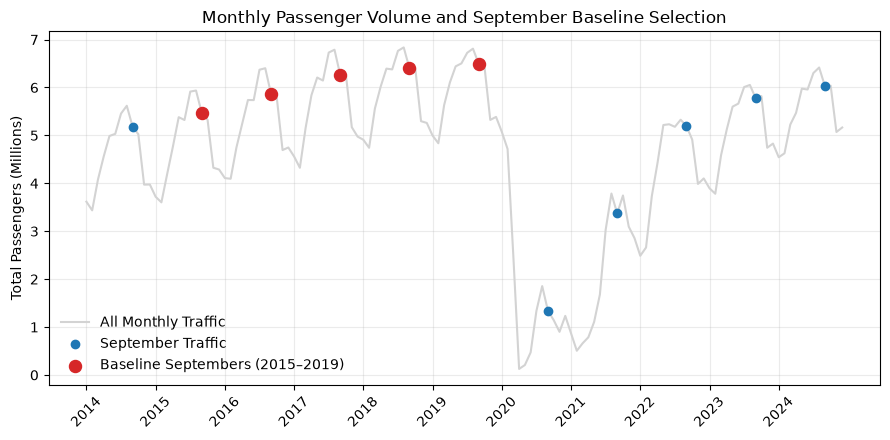

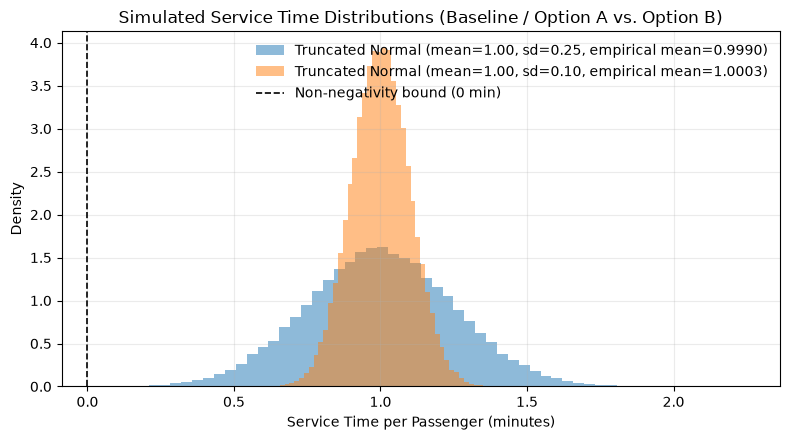

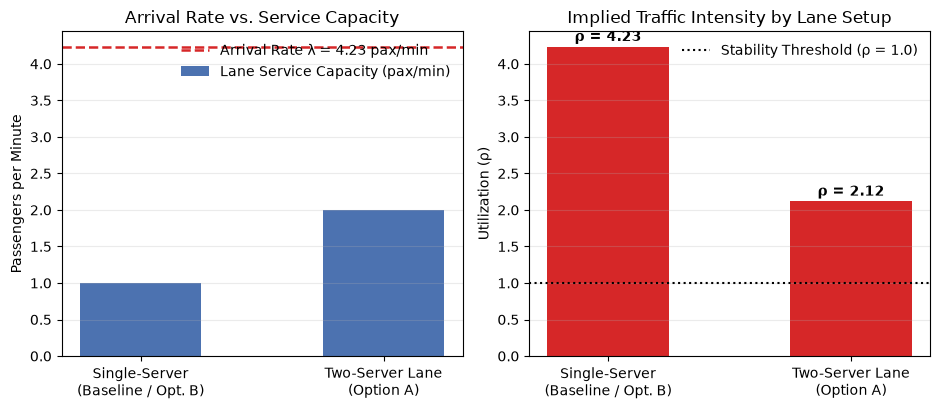

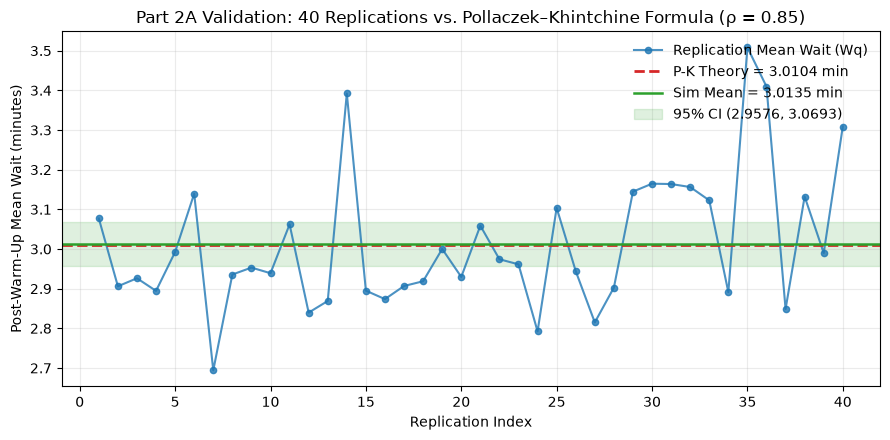

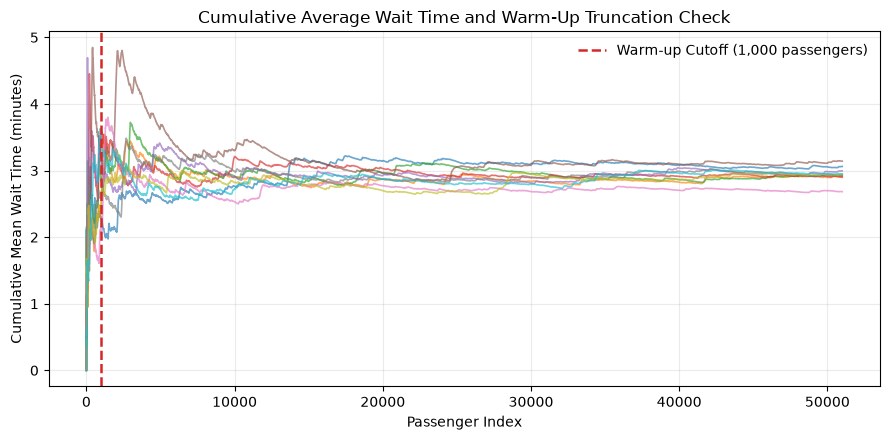

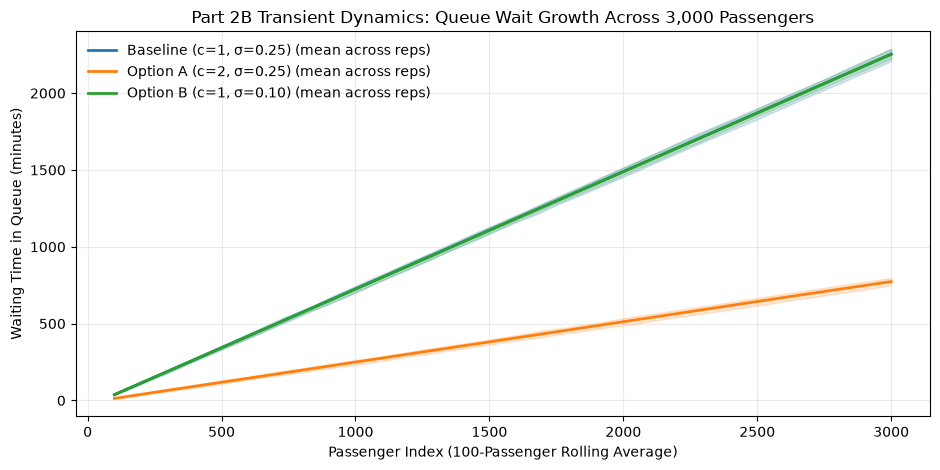

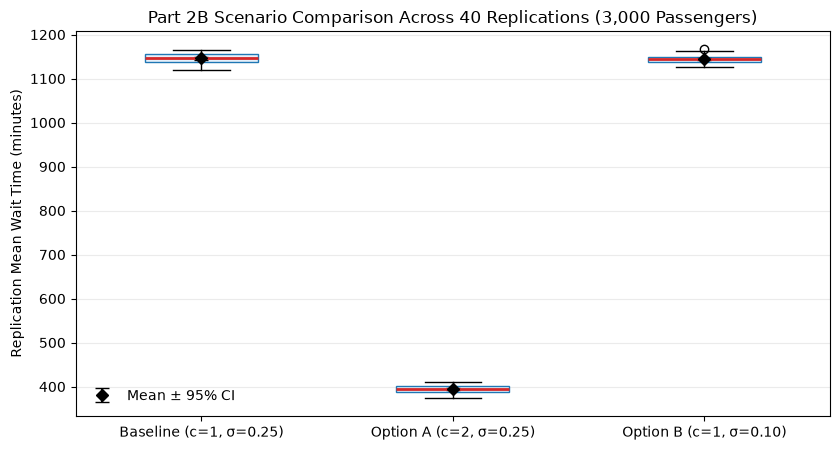

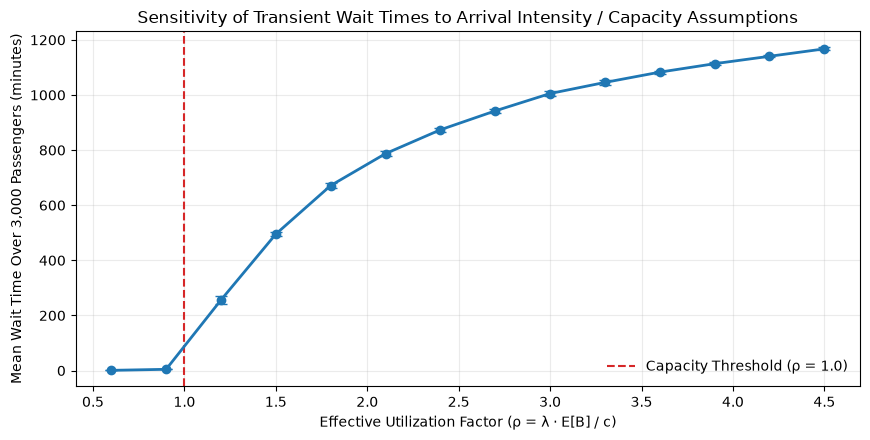

In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt

# 1. Load saved Part 2A and Part 2B results from disk (skip if still in memory)
with open("part2a_results.txt", "r", encoding="utf-8") as f:
    p2a = json.load(f)

lam_test = p2a["lam_test"]
Wq_theory = p2a["Wq_theory"]
Wq_sim = p2a["Wq_sim"]
ci = tuple(p2a["ci"])
rep_means = np.array(p2a["rep_means"])

with open("part2b_results.txt", "r", encoding="utf-8") as f:
    p2b = json.load(f)

scenario_waits_dict = {k: np.array(v) for k, v in p2b["scenario_waits_dict"].items()}
rep_means_dict = {k: np.array(v) for k, v in p2b["rep_means_dict"].items()}
lam = p2b["meta"]["lam"]
E_B = p2b["meta"]["E_B"]
N_PAX_2B = p2b["meta"]["N_PAX_2B"]

# 2. Part 1 Plots (Data & Modeling Assumptions)
fig1, ax1 = plot_historical_september_trend(df, baseline_years=(2015, 2019))
plt.show()

fig2, ax2 = plot_service_time_distribution(mean_s=E_B, sd_list=(0.25, 0.10))
plt.show()

fig3, ax3 = plot_utilization_regime(lam=lam, e_b=E_B)
plt.show()

# 3. Part 2A Plots (Simulator Validation)
fig4, ax4 = plot_pk_validation(
    rep_means=rep_means,
    wq_theory=Wq_theory,
    wq_sim=Wq_sim,
    ci=ci,
    alpha=0.05,
)
plt.show()

fig5, ax5 = plot_warmup_convergence(
    lam_test=lam_test,
    mean_s=E_B,
    sd_s=0.25,
    n_servers=1,
    n_passengers=51_000,
    warmup=1000,
)
plt.show()

# 4. Part 2B Plots (Intervention Hypothesis Testing)
fig6, ax6 = plot_transient_trajectories(scenario_waits_dict, window=100)
plt.show()

fig7, ax7 = plot_scenario_hypothesis_comparison(rep_means_dict, alpha=0.05)
plt.show()

# 5. Sensitivity & Leadership Trade-Off Plot
fig8, ax8 = plot_arrival_sensitivity(
    rho_values=np.linspace(0.6, 4.5, 14),
    mean_s=E_B,
    sd_s=0.25,
    n_servers=1,
    n_passengers=N_PAX_2B,
)
plt.show()

              scenario  baseline_mean  scenario_mean  improvement   ci_lower   ci_upper    adjusted_p  significant
Option A (c=2, σ=0.25)    1145.835437     394.177398   751.658039 745.899051 757.417027 7.149453e-110         True
Option B (c=1, σ=0.10)    1145.835437    1144.608724     1.226713  -4.556148   7.009575  6.285512e-01        False


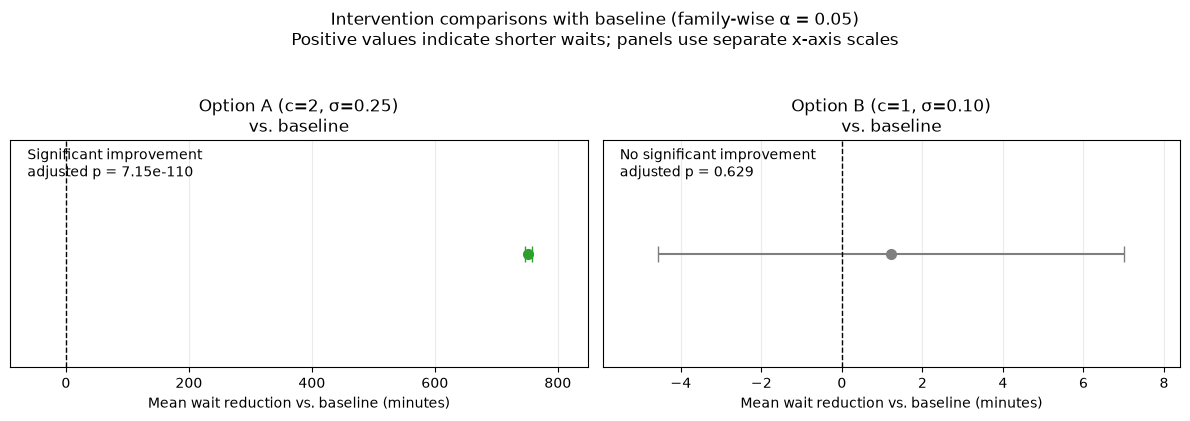

In [43]:
def plot_baseline_comparisons(rep_means_dict, baseline_name="Baseline (c=1, σ=0.25)", alpha=0.05):
    """Plot intervention wait reductions vs. baseline and test for improvement.

    Uses one-sided Welch t-tests and Bonferroni-adjusted p-values and
    confidence intervals for the baseline comparisons.
    """
    if baseline_name not in rep_means_dict:
        raise ValueError(f"Baseline scenario {baseline_name!r} was not found.")
    if not 0 < alpha < 1:
        raise ValueError("alpha must be between 0 and 1.")

    baseline = np.asarray(rep_means_dict[baseline_name], dtype=float)
    if baseline.ndim != 1 or len(baseline) < 2 or not np.isfinite(baseline).all():
        raise ValueError("Baseline replication means must be a finite 1D array with at least two values.")

    comparisons = []
    for name, values in rep_means_dict.items():
        if name == baseline_name:
            continue
        intervention = np.asarray(values, dtype=float)
        if intervention.ndim != 1 or len(intervention) < 2 or not np.isfinite(intervention).all():
            raise ValueError(f"Replication means for {name!r} must be a finite 1D array with at least two values.")

        test = stats.ttest_ind(intervention, baseline, equal_var=False, alternative="less")
        intervention_term = intervention.var(ddof=1) / len(intervention)
        baseline_term = baseline.var(ddof=1) / len(baseline)
        standard_error = np.sqrt(intervention_term + baseline_term)
        degrees_freedom = (intervention_term + baseline_term) ** 2 / (
            intervention_term**2 / (len(intervention) - 1)
            + baseline_term**2 / (len(baseline) - 1)
        )

        improvement = baseline.mean() - intervention.mean()
        n_comparisons = len(rep_means_dict) - 1
        critical_value = stats.t.ppf(1 - alpha / (2 * n_comparisons), degrees_freedom)
        margin = critical_value * standard_error
        adjusted_p = min(float(test.pvalue) * n_comparisons, 1.0)

        comparisons.append({
            "scenario": name,
            "baseline_mean": baseline.mean(),
            "scenario_mean": intervention.mean(),
            "improvement": improvement,
            "ci_lower": improvement - margin,
            "ci_upper": improvement + margin,
            "adjusted_p": adjusted_p,
            "significant": adjusted_p < alpha,
        })

    if not comparisons:
        raise ValueError("At least one intervention scenario is required for comparison.")

    fig, axes = plt.subplots(1, len(comparisons), figsize=(6 * len(comparisons), 4), squeeze=False)
    axes = axes.ravel()
    for ax, result in zip(axes, comparisons):
        estimate = result["improvement"]
        lower_error = estimate - result["ci_lower"]
        upper_error = result["ci_upper"] - estimate
        color = "#2ca02c" if result["significant"] else "#7f7f7f"
        ax.errorbar(estimate, 0, xerr=[[lower_error], [upper_error]], fmt="o", capsize=6, color=color, markersize=7)
        ax.axvline(0, color="black", linestyle="--", linewidth=1)
        ax.set_yticks([])
        ax.set_xlabel("Mean wait reduction vs. baseline (minutes)")
        ax.set_title(f"{result['scenario']}\nvs. baseline")
        ax.grid(axis="x", alpha=0.25)

        conclusion = "Significant improvement" if result["significant"] else "No significant improvement"
        ax.text(0.03, 0.97, f"{conclusion}\nadjusted p = {result['adjusted_p']:.3g}", transform=ax.transAxes, va="top")
        x_low = min(result["ci_lower"], 0)
        x_high = max(result["ci_upper"], 0)
        padding = max((x_high - x_low) * 0.12, 0.1)
        ax.set_xlim(x_low - padding, x_high + padding)

    fig.suptitle(
        f"Intervention comparisons with baseline (family-wise α = {alpha:.2f})\n"
        "Positive values indicate shorter waits; panels use separate x-axis scales",
        y=1.04,
    )
    fig.tight_layout()
    results = pd.DataFrame(comparisons)
    return fig, axes, results


fig9, ax9, baseline_comparison_results = plot_baseline_comparisons(
    rep_means_dict,
    baseline_name="Baseline (c=1, σ=0.25)",
    alpha=0.05,
)
print(baseline_comparison_results.to_string(index=False))
plt.show()

## Assignment 2 — answers and interpretation

### Part 1: September arrival rate

The September baseline uses the five pre-pandemic observations from 2015–2019. Their mean is **6,096,447.6 passengers per month**. Under the assignment's 30-day, 16-operating-hour, 50-lane assumptions:

`λ = 6,096,447.6 / (30 × 16 × 50 × 60) = 4.2336 passengers per minute per lane`.

This is the homogeneous Poisson rate for the representative lane; the corresponding exponential interarrival time has mean `1/λ = 0.2362 minutes` (about 14.2 seconds). The rate is a uniformized peak-month average, not a claim that real within-day arrivals are uniform. The historical-traffic and September-baseline plot shows which five observations were selected.

With mean service time `E[B] = 1 minute`, utilization is `ρ = λE[B]/c`. It is **4.2336** for the one-server baseline and Option B, and **2.1168** for Option A's two servers. All exceed 1, so none of these peak-rate systems has a steady state; reducing service-time variability alone does not change utilization. This agrees with the slides' utilization/stability rule.

### Part 2A: validate against M/G/1 theory

For the stable validation case, `ρtarget = 0.85`, so `λtest = 0.85` and `ρtest = 0.85 < 1`. Using the assignment's service moments, `E[S²] = E[B]² + σ² = 1.0625 minutes²`. The Pollaczek–Khintchine result is

`Wq,theory = λtest E[S²] / (2(1 − ρtest)) = 3.0104 minutes`.

The notebook runs **40 independent replications**, simulating 51,000 passengers per replication and discarding the first 1,000 waits. Test `H₀: μWq = Wq,theory` against `H₁: μWq ≠ Wq,theory` with a two-sided one-sample t-test on the replication means (`α = 0.05`). The simulated mean is **3.0135 minutes**, with 95% CI **(2.9576, 3.0693)**; `t(39) = 0.1114`, `p = 0.9119`. We **fail to reject H₀**: the theoretical value lies within the interval, so this test finds no evidence of a mismatch and supports simulator validation. This is evidence of consistency, not proof that the simulator is correct in every configuration.

The P–K validation figure overlays replication means, the theoretical value, and the confidence interval; the cumulative-mean plot visualizes the warm-up period. The service-time plot shows the non-negative, resampled normal distributions used by the simulator.

### Part 2B: intervention tests

Each scenario uses the Part 1 arrival rate, **40 independent replications**, and **3,000 passengers per replication**, with no warm-up deletion. For each intervention, the notebook tests whether its mean wait is lower than baseline using a one-sided Welch t-test. The two baseline comparisons use Bonferroni-adjusted p-values (`α = 0.05`); the plotted intervals are family-wise 95% intervals for the wait reduction `baseline − intervention`.

| Scenario | Mean wait (min) | Reduction vs. baseline (min) | Adjusted 95% CI for reduction (min) | Adjusted p | Significant? |
| --- | ---: | ---: | ---: | ---: | --- |
| Baseline (1 server, σ = 0.25) | 1,145.84 | — | — | — | — |
| Option A (2 servers, σ = 0.25) | 394.18 | 751.66 | (745.90, 757.42) | 7.15 × 10⁻¹¹⁰ | **Yes** |
| Option B (1 server, σ = 0.10) | 1,144.61 | 1.23 | (−4.56, 7.01) | 0.6286 | **No** |

At the 5% level, **Option A shows a statistically significant improvement over baseline; Option B does not**. The baseline-comparison plot makes the key distinction visible: Option A's interval is wholly above zero, while Option B's includes zero. The transient trajectory and replication-distribution plots show the same ordering across the finite 3,000-passenger runs. Their shaded trajectory bands are replication percentiles, not confidence intervals for the mean.

### Recommendation and alternative strategy

Prefer **Option A** over Option B if choosing between the tested interventions: it cuts mean waiting time by about 752 minutes in these runs, whereas reducing variability at the same mean service time has no statistically detectable benefit here. However, Option A still has `ρ = 2.1168 > 1`; it reduces transient waits but does not make the modeled system stable. To address the overload, increase effective service capacity or route arrivals across additional queues, and consider peak-period appointment staggering or process changes that reduce the **mean** service time. For a one-minute mean service time, at least five equivalent servers per representative arrival stream are needed just to make `ρ < 1` (`4.2336/5 = 0.8467`); operational planning should include a safety margin.

### Theory alignment

The simulator generates exponential interarrival times for a homogeneous Poisson process, processes arrival/departure events from a future-event list, and serves the waiting line FIFO. These choices follow the course slides on Poisson/exponential arrivals (slides 56 and 62), FIFO/Kendall queue notation (slides 73–75), event scheduling (`heapq`, slide 81), and the utilization stability condition (slide 79).